In [1]:
import time
import os

import torch
import torchvision
import matplotlib.pyplot as plt

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

DIR_NAME = os.getcwd()
print("Рабочая директория:", DIR_NAME)

Рабочая директория: /content


In [2]:
BATCH_SIZE = 64
LEARNING_RATE = 0.001 # для AdamW стандарт (хорошо сходится)
EPOCHS = 20
CONV_KERNEL = (3, 3) # оптимально по производительности и точности. Ядро должно быть нечетным, так как нечетное ядро не имеет центра и невозможно будет сохранить размер изображения за счет отступа
NUM_CLASSES = 10 # число классов в CIFAR 10
INPUT_CHANNELS = 3 # число каналов входного изображения (RGB)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

Устройство: cuda


In [3]:
mean = (0.5, 0.5, 0.5) # среднее
std = (0.5, 0.5, 0.5) # ст. отклонение
#по сути, это контейнер для операций
train_transform = torchvision.transforms.Compose([torchvision.transforms.RandomCrop(32, padding=4), # без него 90.22%. точность на 0.6% падает на тесте. Добавляет нулевую рамку padding=4 вокруг изобр (получаем 40 на 40). далее случайно вырезаем из 40х40 32х32.
    torchvision.transforms.RandomHorizontalFlip(),    # отражение с вероятностью 50%
    torchvision.transforms.ToTensor(), # из [0, 255] делаем [0, 1]
    torchvision.transforms.Normalize(mean, std)]) # из [0, 1] делаем [-1, 1]

test_transform = torchvision.transforms.Compose([torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean, std)])

train_data = torchvision.datasets.CIFAR10(DIR_NAME, train=True, download=True, transform=train_transform) # Загружаем обучающую выборку CIFAR-10
test_data = torchvision.datasets.CIFAR10(DIR_NAME, train=False, download=True, transform=test_transform)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True) # оборачиваем train в итератор по батчам (DataLoader); shuffle=True - перемешивание train на перед каждой эпохой; num_workers=2 - 2 фоновых процесса готовят следующий батч, пока модель учится; данные в «pinned» память для быстрой передачи на GPU (снижает время)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Обучающая выборка (изображения): {train_data.data.shape}")
print(f"Обучающая выборка (метки):       {len(train_data.targets)}")
print(f"Тестовая выборка (изображения):  {test_data.data.shape}")
print(f"Тестовая выборка (метки):        {len(test_data.targets)}")
print(f"Классы: {train_data.classes}")

100%|██████████| 170M/170M [16:20<00:00, 174kB/s]


Обучающая выборка (изображения): (50000, 32, 32, 3)
Обучающая выборка (метки):       50000
Тестовая выборка (изображения):  (10000, 32, 32, 3)
Тестовая выборка (метки):        10000
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


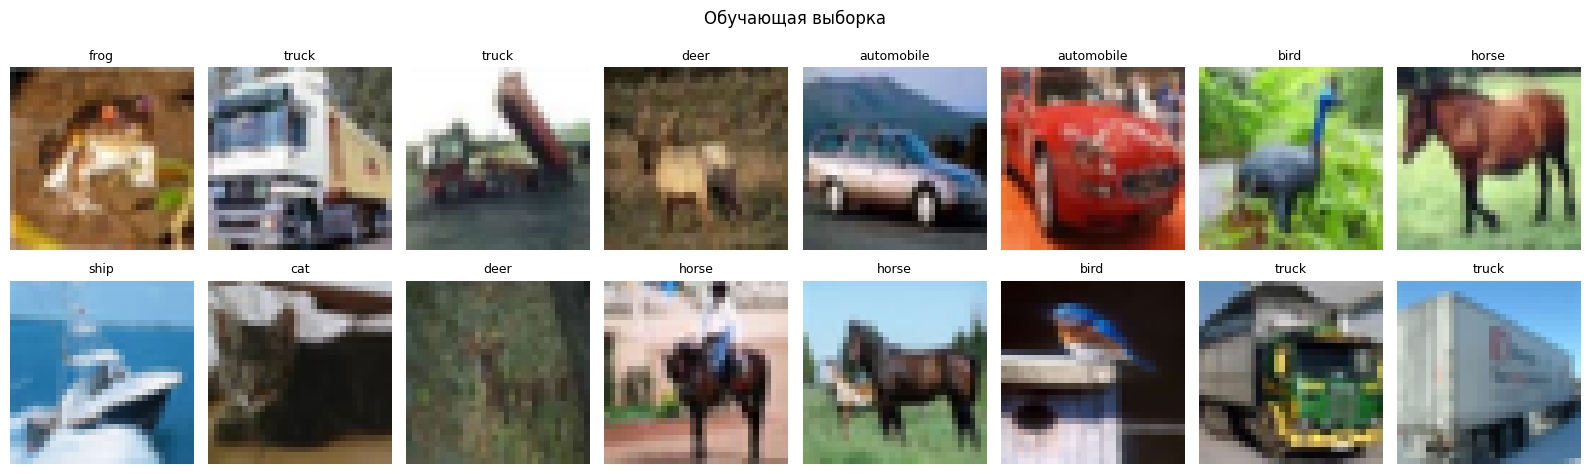

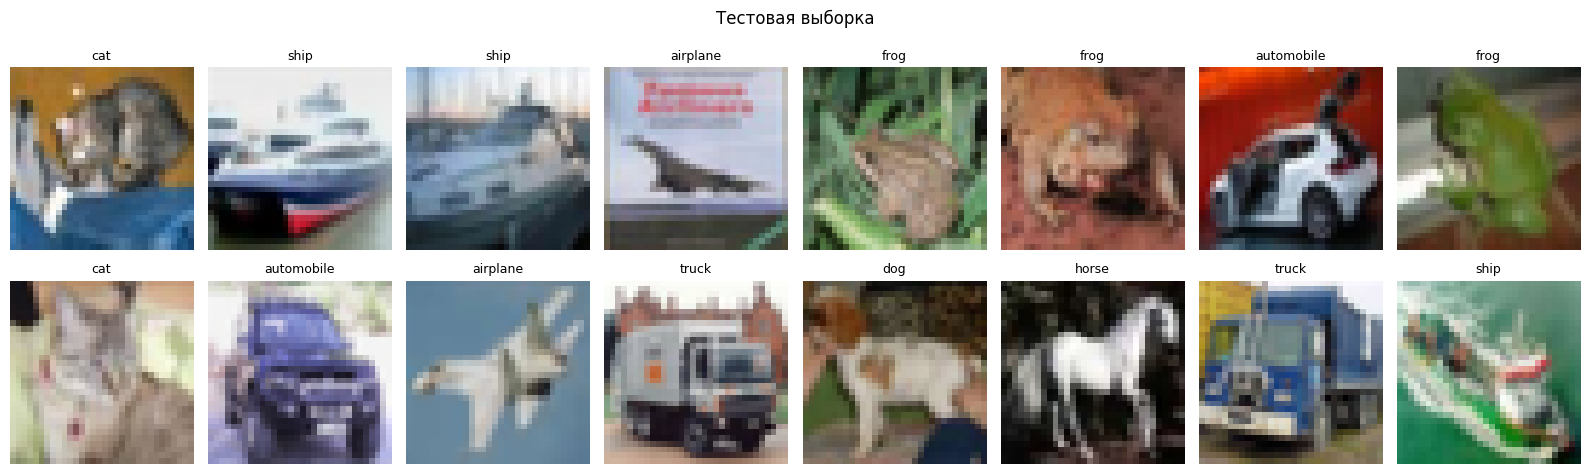

In [4]:
def show_examples(dataset, n_rows=2, n_cols=8, title="Примеры изображений"):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2.5 * n_rows))
    fig.suptitle(title)
    for ax, idx in zip(axes.flat, range(n_rows * n_cols)):
        ax.imshow(dataset.data[idx])
        ax.set_title(dataset.classes[dataset.targets[idx]], fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_examples(train_data, title="Обучающая выборка")
show_examples(test_data, title="Тестовая выборка")

In [9]:
def conv_block(in_channels, out_channels):
    layers = [torch.nn.Conv2d(in_channels, out_channels, kernel_size=CONV_KERNEL, padding=1), # сверточный слой
        torch.nn.BatchNorm2d(out_channels), # нормализация по батчу
        torch.nn.ReLU(inplace=True)] # функция активации
    return torch.nn.Sequential(*layers)


class ConvNet(torch.nn.Module):
    def __init__(self, input_channels=INPUT_CHANNELS, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = torch.nn.Sequential(
            conv_block(input_channels, 64),
            conv_block(64, 64),
            torch.nn.MaxPool2d(2),
            conv_block(64, 128),
            conv_block(128, 128),
            torch.nn.MaxPool2d(2),
            conv_block(128, 256),
            conv_block(256, 256),
            torch.nn.MaxPool2d(2),
            conv_block(256, 512),
            conv_block(512, 512))
        self.pool = torch.nn.AdaptiveAvgPool2d((1, 1)) # из (B, 512, 4, 4) делаем (B, 512, 1, 1)
        self.dropout = torch.nn.Dropout(0.3) # убиваем 30% случайных признаков
        self.classifier = torch.nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = x.flatten(1) # [B, 512, 1, 1] превращаем в [B, 512]
        x = self.dropout(x)       #  применяем dropout
        x = self.classifier(x)
        return x


model = ConvNet().to(device)

criterion = torch.nn.CrossEntropyLoss() # так как задача классификации и 10 классов
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4) ##
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10], gamma=0.1) # на 10 и 15 эпохах lr уменьшится в 10 раз. это позволит точнее попасть в минимум ошибки

In [10]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total += images.size(0)

    return total_loss / total, total_correct / total


train_loss_hist, train_acc_hist = [], []

print("Начало обучения")
t_start = time.time()
for epoch in range(1, EPOCHS+1):
    t_epoch = time.time()
    loss, acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    scheduler.step()

    train_loss_hist.append(loss)
    train_acc_hist.append(acc)
    print(f"Эпоха {epoch:2d}/{EPOCHS} | время {time.time() - t_epoch:6.2f} с | "
          f"loss {loss:.4f} | acc {acc:.4f}")
print(f"Общее время обучения: {time.time() - t_start:.2f} с")

Начало обучения
Эпоха  1/20 | время  21.78 с | loss 1.3101 | acc 0.5195
Эпоха  2/20 | время  22.72 с | loss 0.8515 | acc 0.7027
Эпоха  3/20 | время  22.62 с | loss 0.6732 | acc 0.7675
Эпоха  4/20 | время  22.03 с | loss 0.5764 | acc 0.8017
Эпоха  5/20 | время  22.52 с | loss 0.5114 | acc 0.8231
Эпоха  6/20 | время  22.24 с | loss 0.4584 | acc 0.8409
Эпоха  7/20 | время  22.04 с | loss 0.4153 | acc 0.8566
Эпоха  8/20 | время  22.84 с | loss 0.3746 | acc 0.8706
Эпоха  9/20 | время  22.25 с | loss 0.3450 | acc 0.8795
Эпоха 10/20 | время  22.10 с | loss 0.3165 | acc 0.8904
Эпоха 11/20 | время  22.87 с | loss 0.2216 | acc 0.9247
Эпоха 12/20 | время  22.05 с | loss 0.1931 | acc 0.9333
Эпоха 13/20 | время  22.18 с | loss 0.1810 | acc 0.9379
Эпоха 14/20 | время  22.78 с | loss 0.1735 | acc 0.9414
Эпоха 15/20 | время  22.03 с | loss 0.1635 | acc 0.9437
Эпоха 16/20 | время  22.06 с | loss 0.1573 | acc 0.9455
Эпоха 17/20 | время  22.72 с | loss 0.1504 | acc 0.9479
Эпоха 18/20 | время  21.74 с | l

In [7]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * images.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, total_correct / total


test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Тест | loss: {test_loss:.4f} | accuracy: {test_acc:.4f}")


Тест | loss: 0.3079 | accuracy: 0.9046


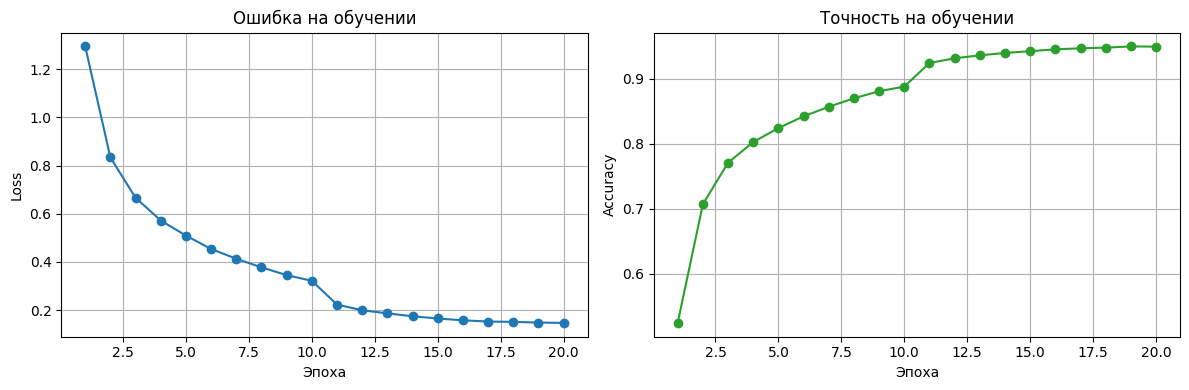

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(range(1, EPOCHS+1), train_loss_hist, marker="o")
ax1.set_xlabel("Эпоха")
ax1.set_ylabel("Loss")
ax1.set_title("Ошибка на обучении")
ax1.grid(True)

ax2.plot(range(1, EPOCHS+1), train_acc_hist, marker="o", color="tab:green")
ax2.set_xlabel("Эпоха")
ax2.set_ylabel("Accuracy")
ax2.set_title("Точность на обучении")
ax2.grid(True)

plt.tight_layout()
plt.show()